# Academic Dropout Risk Analysis: Exploratory Data Analysis

**Question:** Which factors are associated with student dropout, and how can at-risk students be identified early?

**Data:** 100,000 students, 34 columns (dataset from Kaggle: [Student Academic Performance & Dropout Risk](https://www.kaggle.com/datasets/mohankrishnathalla/student-academic-performance-and-dropout-risk)). Target: `dropout` (1 = dropped out).

1. **Contents:** Libraries · 2. Setup · 3. General structure · 4. Exploratory data analysis (categorical, binary and attendance) · 5. Numerical features and interactions · 6. Key findings

# 1. Libraries

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Setup

In [108]:

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/raw/student_dropout_risk_2026.csv")

print(f"Dataset shape: {df.shape}")
print(f"Number of observations: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
df.head()

Dataset shape: (100000, 34)
Number of observations: 100,000
Number of columns: 34


,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,course_type,study_mode,semester,international_student,admission_grade,previous_qualification_grade,units_enrolled,units_passed,units_failed,gpa_semester_1,gpa_semester_2,attendance_rate,assignments_submitted_rate,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,24,STEM,Online,7,0,164.6,165.1,11,11,0,3.44,2.55,77.3,75.0,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,0,Arts & Humanities,Full-time,6,1,175.2,164.1,14,11,3,2.56,2.53,52.1,80.1,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,16,Arts & Humanities,Full-time,3,0,126.0,179.3,17,14,3,3.43,2.73,100.0,67.8,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,0,Business,Full-time,1,0,75.5,161.9,13,11,2,2.51,2.10,83.9,100.0,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,0,Health Sciences,Part-time,2,0,89.0,101.8,8,7,1,3.93,2.88,61.6,100.0,4,7.4,1,0,7,0,10,24,5.8,0


# 3. General structure of dataset

The dataset contains 100,000 observations and 34 columns, including student-related demographic, academic, financial, and behavioral variables.

The initial inspection reveals the following:

- No missing values were detected.

- No duplicated rows or duplicated student IDs were found.

- The dataset contains numerical and categorical variables.

- Although the dataset appears complete from a structural perspective, further validation is required to identify potentially implausible values and inconsistencies.

The absence of missing values and duplicates does not necessarily guarantee data quality. Additional checks are needed to assess the validity of the observations.

In [109]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   person_id                     100000 non-null  int64  
 1   age                           100000 non-null  int64  
 2   gender                        100000 non-null  str    
 3   nationality                   100000 non-null  str    
 4   first_generation              100000 non-null  int64  
 5   disability_status             100000 non-null  int64  
 6   family_income_level           100000 non-null  str    
 7   scholarship_holder            100000 non-null  int64  
 8   tuition_up_to_date            100000 non-null  int64  
 9   part_time_job                 100000 non-null  int64  
 10  weekly_work_hours             100000 non-null  int64  
 11  course_type                   100000 non-null  str    
 12  study_mode                    100000 non-null  str    
 

In [110]:
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated student IDs:", df["person_id"].duplicated().sum())

Missing values: 0
Duplicated rows: 0
Duplicated student IDs: 0


The target variable, dropout, is distributed as follows:

- Approximately 68% of students did not drop out.

- Approximately 32% of students dropped out.

The dataset presents a moderate class imbalance, with non-dropout cases being more frequent than dropout cases. Although this imbalance is not extreme, it should be considered when evaluating future classification models.

In particular, accuracy alone may not be sufficient to assess model performance. Metrics such as precision, recall, F1-score, and ROC-AUC should also be considered.

In [111]:
print(df["dropout"].value_counts())
print()
print(df["dropout"].value_counts(normalize=True).round(3))

dropout
0    67996
1    32004
Name: count, dtype: int64

dropout
0    0.68
1    0.32
Name: proportion, dtype: float64


We can see several insights
- <b>Age</b>: the mean age is approximately 21.52 years, with values ranging from 15 to 30.

- <b>Academic performance</b>: the mean GPA decreases from 2.57 in semester 1 to 1.98 in semester 2. This difference deserves further investigation, although aggregate statistics alone do not establish why it occurs.

- <b>Admission grade</b>: the mean is approximately 133.15, while the minimum is 5.5. The minimum value should be investigated to determine whether it represents a valid observation or a potential data-quality issue.

These statistics provide an initial overview of the dataset. Distribution plots and further validation checks are needed before drawing stronger conclusions.

In [112]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_id,100000.0,50000.500000,28867.657797,1.0,25000.75,50000.50,75000.25,100000.0
age,100000.0,21.520840,3.399468,15.0,19.00,21.00,24.00,30.0
first_generation,100000.0,0.420130,0.493582,0.0,0.00,0.00,1.00,1.0
disability_status,100000.0,0.208770,0.406432,0.0,0.00,0.00,0.00,1.0
scholarship_holder,100000.0,0.589700,0.491891,0.0,0.00,1.00,1.00,1.0
tuition_up_to_date,100000.0,0.784860,0.410921,0.0,1.00,1.00,1.00,1.0
part_time_job,100000.0,0.481920,0.499676,0.0,0.00,0.00,1.00,1.0
weekly_work_hours,100000.0,8.744620,10.232842,0.0,0.00,0.00,18.00,40.0
semester,100000.0,3.617970,2.112763,1.0,2.00,3.00,5.00,8.0
international_student,100000.0,0.180940,0.384970,0.0,0.00,0.00,0.00,1.0


we can see the categorical features

In [113]:
cat_cols = df.select_dtypes(exclude="number").columns
for col in cat_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts().head(10))
    print()

--- gender ---
gender
Female    50731
Male      47224
Other      2045
Name: count, dtype: int64

--- nationality ---
nationality
USA            29979
India          11994
China          10013
Brazil          6873
Mexico          6149
UK              6050
Nigeria         5921
Germany         4072
South Korea     4060
Philippines     3956
Name: count, dtype: int64

--- family_income_level ---
family_income_level
Middle    40213
Low       34809
High      24978
Name: count, dtype: int64

--- course_type ---
course_type
STEM                     30141
Business                 24986
Arts & Humanities        18024
Health Sciences          14941
Law & Social Sciences    11908
Name: count, dtype: int64

--- study_mode ---
study_mode
Full-time    65096
Part-time    21975
Online       12929
Name: count, dtype: int64



The validation checks reveal two relevant findings:

- Age: 7,753 students are younger than 17. Given the apparent higher-education context, these observations deserve further investigation. However, age alone is not sufficient to conclude that the records are invalid or that the dataset is synthetic.

- Academic units: `units_passed` + `units_failed` equals `units_enrolled` in every observation. This is expected, since the dataset documentation defines `units_failed` as `units_enrolled` minus `units_passed`.

These checks identify a potential area for further validation while confirming that the tested academic-unit constraint is satisfied across all observations.
Additional domain-specific checks should be performed before deciding whether any observations require correction or removal.

In [114]:
print("Students under 17y/o:", (df["age"] < 17).sum())
print("Rows where passed + failed != enrolled:",
      ((df["units_passed"] + df["units_failed"]) != df["units_enrolled"]).sum())

Students under 17y/o: 7753
Rows where passed + failed != enrolled: 0


# 4. Exploratory Data Analysis (EDA)

Family income level shows one of the clearest differences in observed dropout rates:

- Low-income students: 42.9% dropout rate.

- Middle-income students: 30.0% dropout rate.

- High-income students: 20.0% dropout rate.

The observed dropout rate is substantially higher among students in the low-income category than among those in the high-income category. The difference between these groups is 22.9 percentage points.

This pattern suggests that family income level may be an important variable to investigate further when studying student dropout risk.

However, these are descriptive, unadjusted comparisons. Further analysis is needed to determine whether the association remains after accounting for other relevant variables.

In [115]:
for col in cat_cols:
    print(f"--- {col} ---")
    print(df.groupby(col)["dropout"].agg(rate="mean", n="size").round(3).sort_values("rate", ascending=False))
    print()

--- gender ---
         rate      n
gender              
Other   0.334   2045
Male    0.320  47224
Female  0.319  50731

--- nationality ---
              rate      n
nationality              
Indonesia    0.330   2982
Germany      0.326   4072
China        0.325  10013
Pakistan     0.324   3030
Australia    0.322    969
India        0.322  11994
UK           0.321   6050
USA          0.320  29979
South Korea  0.319   4060
Brazil       0.318   6873
Nigeria      0.318   5921
Philippines  0.318   3956
Mexico       0.314   6149
Egypt        0.313   1985
Canada       0.301   1967

--- family_income_level ---
                      rate      n
family_income_level              
Low                  0.429  34809
Middle               0.300  40213
High                 0.200  24978

--- course_type ---
                        rate      n
course_type                        
Arts & Humanities      0.321  18024
Health Sciences        0.321  14941
STEM                   0.321  30141
Business         

Several binary variables show noticeable differences in observed dropout rates:
- ```first_generation```: students who are the first in their immediate family to attend college have a higher dropout rate (37.4% vs. 28.1% for the rest)
- ```disability_status```: we can see that students who have a disability have a higher dropout rate (36.5% for disabled students vs 30.8% for the rest)
- ```tuition_up_to_date```: one of the most relevant features. Students without up-to-date tuition have a higher dropout rate (44.2% vs. 28.7% for students who are up to date).
- ```part_time_job```: students who have a part-time job are more prone to dropout (39.8% for students who have a job vs 24.7% for the rest)
  
These descriptive differences make tuition status, employment, and first-generation status particularly interesting candidates for further investigation.
By contrast, scholarship holders show a slightly lower dropout rate (31.1% versus 33.2%), while international status shows virtually no difference (32.1% versus 32.0%).
These findings describe associations in the observed data and should not be interpreted as evidence of causation.

In [116]:
bin_cols = ["first_generation", "disability_status", "scholarship_holder",
            "tuition_up_to_date", "part_time_job", "international_student"]

for col in bin_cols:
    print(f"--- {col} ---")
    print(df.groupby(col)["dropout"].mean().round(3))
    print()

--- first_generation ---
first_generation
0    0.281
1    0.374
Name: dropout, dtype: float64

--- disability_status ---
disability_status
0    0.308
1    0.365
Name: dropout, dtype: float64

--- scholarship_holder ---
scholarship_holder
0    0.332
1    0.311
Name: dropout, dtype: float64

--- tuition_up_to_date ---
tuition_up_to_date
0    0.442
1    0.287
Name: dropout, dtype: float64

--- part_time_job ---
part_time_job
0    0.247
1    0.398
Name: dropout, dtype: float64

--- international_student ---
international_student
0    0.320
1    0.321
Name: dropout, dtype: float64



Some categorical variables show comparatively small differences in dropout rates:

- Gender: dropout rates are approximately 31.9% for female students, 32.0% for male students, and 33.4% for students identifying as Other.

- Nationality: observed dropout rates range from 30.1% for Canadian students to 33.0% for Indonesian students.

- Course type: dropout rates are very similar across the five course categories, ranging from 31.7% to 32.1%.

- International status: the dropout rate is approximately 32.1% for international students and 32.0% for non-international students.

- Study mode: online students have the lowest observed dropout rate (29.2%), while part-time students have the highest (33.7%).

- Scholarship status: scholarship holders show a slightly lower dropout rate than non-holders (31.1% versus 33.2%).

Overall, course type and international status show very small differences in these unadjusted comparisons. Gender and nationality also show relatively modest differences, although the observed rates vary across categories.

These descriptive results do not establish statistical significance or rule out relationships that may emerge after accounting for other variables.

<br>

Attendance rate shows a clear negative descriptive association with student dropout.

The observed dropout rate decreases across attendance categories, from approximately 59.2% among students with attendance of 50% or less to 16.1% among students with attendance above 90%.

This represents a difference of 43.1 percentage points between the two groups.

The pattern suggests that attendance may be a useful variable for identifying students who could benefit from additional academic support. However, this analysis is descriptive and does not establish a causal relationship. Further investigation is needed to determine whether the association remains after accounting for other student characteristics.

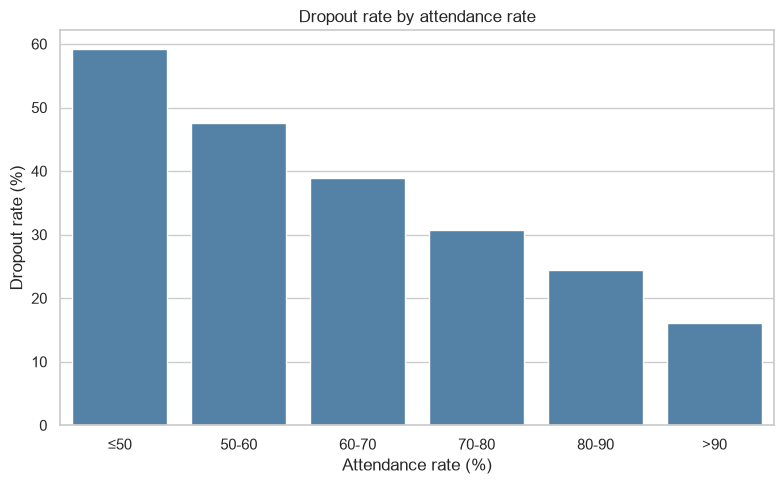

In [117]:
df["attendance_bin"] = pd.cut(df["attendance_rate"], bins=[0, 50, 60, 70, 80, 90, 100], labels=["≤50", "50-60", "60-70", "70-80", "80-90", ">90"], include_lowest=True)
rate = df.groupby("attendance_bin", observed=True)["dropout"].mean() * 100

plt.figure(figsize=(8, 5))
sns.barplot(x=rate.index.astype(str), y=rate.values, color="steelblue")
plt.title("Dropout rate by attendance rate")
plt.xlabel("Attendance rate (%)")
plt.ylabel("Dropout rate (%)")
plt.tight_layout()
plt.savefig("../reports/figures/dropout_by_attendance.png", dpi=150)
plt.show()

# 5. Numerical features and interactions

## 5.1 Correlation with dropout

Pearson correlation between each numeric feature and `dropout` (binary variables are included as 0/1).

- **Moderate association:** `gpa_semester_1` (-0.57), `gpa_semester_2` (-0.52) and `units_failed` (+0.47). Lower grades and more failed units go together with a higher dropout rate.
- **Weak association (|r| between 0.20 and 0.29):** `attendance_rate`, `assignments_submitted_rate`, `units_passed`, `library_visits_per_month` and `lms_logins_per_week` (all negative), and `missed_deadlines` (positive).
- **Very weak association (|r| around 0.10 to 0.18):** `weekly_work_hours`, `part_time_job`, `stress_level`, `first_generation`, `tuition_up_to_date` and `admission_grade`.
- **Very weak association (|r| between 0.04 and 0.10):** `disability_status` (+), `satisfaction_score`, `extracurricular_activities` and `sleep_hours` (all negative).
- **Practically no association (|r| < 0.04):** `age`, `international_student`, `commute_time_mins`, `units_enrolled`, `mental_health_support`, `scholarship_holder`, `semester` and `previous_qualification_grade`.

Pearson correlation only captures linear association and does not imply causation. The magnitude ranges above are a rule of thumb. Some of the strongest variables (grades, units passed/failed) may be recorded close to the time of dropout. The Kaggle description states that `gpa_semester_2` is measured after the second semester, but the descriptions reviewed do not say when dropout is recorded, so their timing should be addressed before modeling.

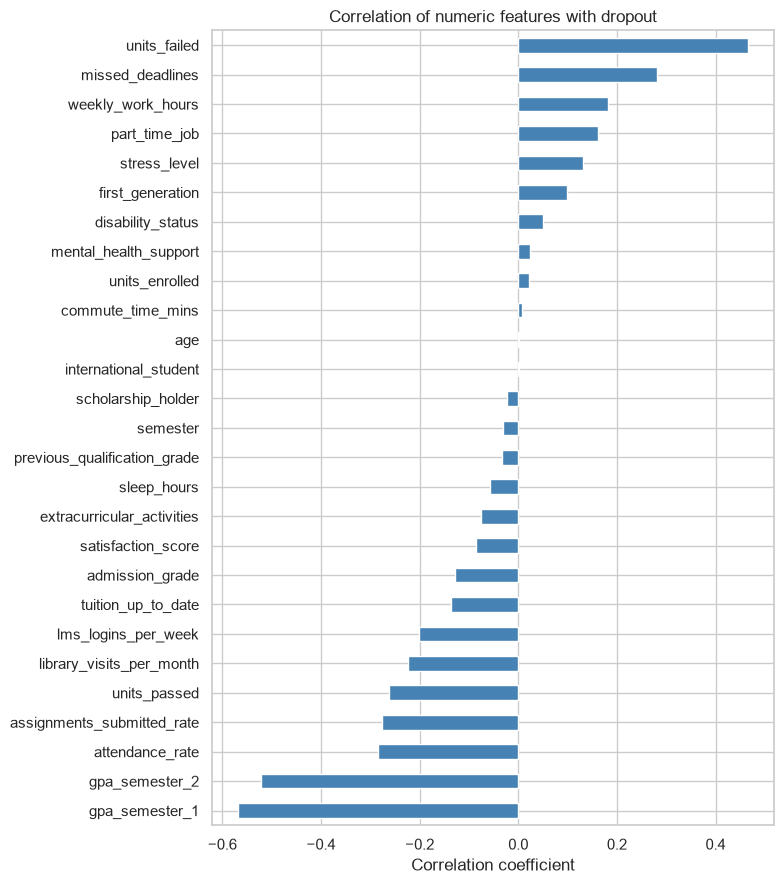

In [118]:
num_cols = df.select_dtypes(include="number").columns.drop(["person_id", "dropout"])
corr = df[list(num_cols) + ["dropout"]].corr()["dropout"].drop("dropout").sort_values()

plt.figure(figsize=(8, 9))
corr.plot(kind="barh", color="steelblue")
plt.title("Correlation of numeric features with dropout")
plt.xlabel("Correlation coefficient")
plt.tight_layout()
plt.savefig("../reports/figures/correlation_with_dropout.png", dpi=150)
plt.show()

## 5.2 Key features per group

The three non-binary features with the highest absolute correlation with `dropout` in section 5.1 are `gpa_semester_1`, `gpa_semester_2` and `units_failed`.

- Median GPA in semester 1: 2.87 for students who stayed vs. 1.92 for those who dropped out. In semester 2: 2.24 vs. 1.44.
- Median failed units: 2 for students who stayed vs. 4 for those who dropped out.
- According to the boxplots, the interquartile ranges of both groups barely overlap or only touch in the three features.
- Both groups show lower GPA in semester 2 than in semester 1, and the gap between groups is present in both semesters (about 0.95 and 0.80 points).

These features do not separate the two groups perfectly: some students who stayed have very low GPA, and some who dropped out have GPA above 3.5. These are descriptive differences and do not imply causation.

Selected features: ['gpa_semester_1', 'gpa_semester_2', 'units_failed']


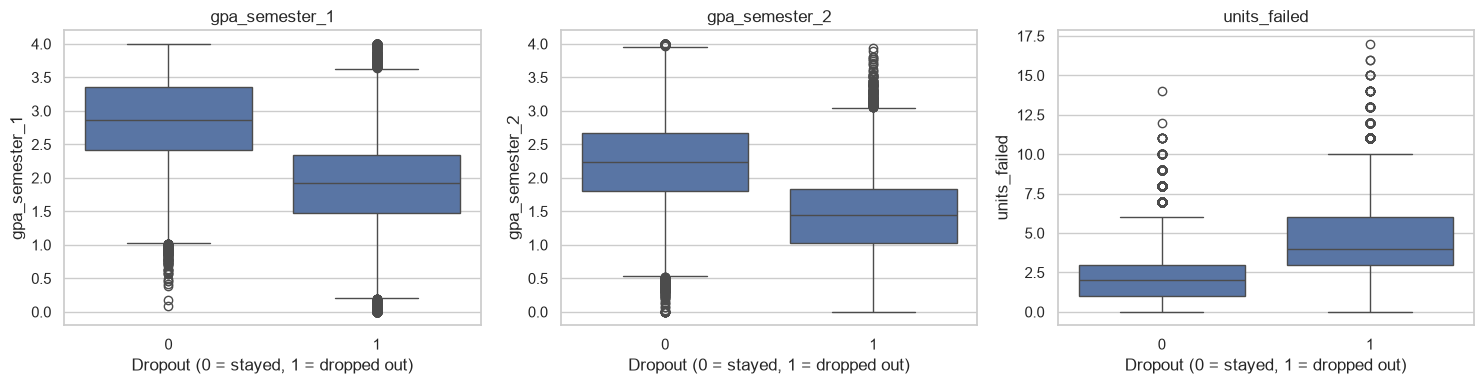

,gpa_semester_1,gpa_semester_2,units_failed
dropout,,,
0,2.87,2.24,2.0
1,1.92,1.44,4.0


In [119]:
# Top 3 non-binary features by absolute correlation with dropout (criterion from 5.1)
non_binary = [c for c in num_cols if df[c].nunique() > 2]
key_features = corr[non_binary].abs().sort_values(ascending=False).head(3).index.tolist()
print("Selected features:", key_features)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, key_features):
    sns.boxplot(data=df, x="dropout", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Dropout (0 = stayed, 1 = dropped out)")
plt.tight_layout()
plt.savefig("../reports/figures/key_features_by_dropout.png", dpi=150)
plt.show()

df.groupby("dropout")[key_features].median().round(2)

## 5.3 Correlation between key features

Correlation matrix among the nine features with |r| ≥ 0.20 with `dropout` (section 5.1).

- **The academic features overlap strongly.** `gpa_semester_1` and `gpa_semester_2` correlate at 0.83, and `units_failed` correlates at -0.75 with `gpa_semester_1` and -0.62 with `gpa_semester_2`. These three should not be read as independent factors.
- **`units_passed`, `units_failed` and `units_enrolled` are linked by definition** (`units_failed` = `units_enrolled` − `units_passed`, verified in the data). `units_passed` is moderately related to the grades (0.45 and 0.37) and weakly to `units_failed` (-0.22), since `units_enrolled` also varies across students.
- **The engagement features** (`attendance_rate`, `assignments_submitted_rate`, `library_visits_per_month`, `lms_logins_per_week`, `missed_deadlines`) are weakly related to each other (at most 0.30 in absolute value), so they do not duplicate one another linearly.
- Engagement features and the academic block are weakly to moderately related (|r| between 0.16 and 0.32 with the two GPAs and units_failed).

Low pairwise correlation does not guarantee that engagement features add information beyond grades. This is checked next.

9 ['gpa_semester_1', 'gpa_semester_2', 'attendance_rate', 'assignments_submitted_rate', 'units_passed', 'library_visits_per_month', 'lms_logins_per_week', 'missed_deadlines', 'units_failed']


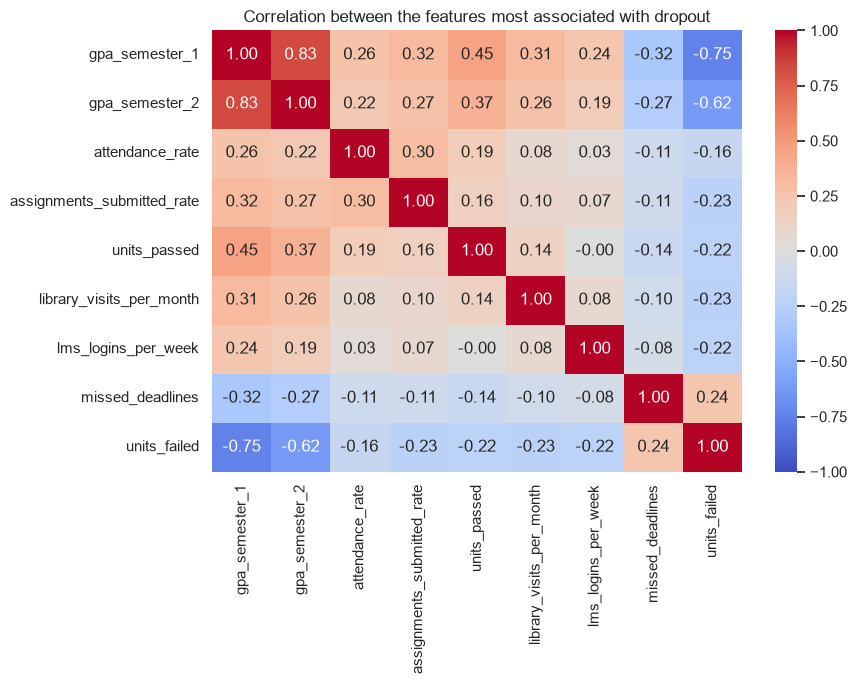

In [120]:
# Features with |r| >= 0.20 with dropout (criterion from section 5.1)
top_features = corr[corr.abs() >= 0.20].index.tolist()
print(len(top_features), top_features)

plt.figure(figsize=(9, 7))
sns.heatmap(df[top_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation between the features most associated with dropout")
plt.tight_layout()
plt.savefig("../reports/figures/top_features_correlation.png", dpi=150)
plt.show()

## 5.4 GPA x attendance

To check whether attendance is just a proxy for grades, students were split into three groups of equal size by `gpa_semester_1` (Low: 0.00–2.23, Mid: 2.24–2.94, High: 2.95–4.00) and dropout rates were compared across attendance bins. These labels are relative to this dataset (terciles), not absolute performance levels. The smallest cell contains 1,455 students.

- **Attendance remains associated with dropout within every GPA group:** from about 83% to 48% (Low GPA), 43% to 15% (Mid GPA) and 12% to 3% (High GPA).
- **GPA remains associated with dropout within every attendance bin:** e.g., about 83%, 43% and 12% for attendance ≤50%, and 48%, 15% and 3% for attendance >90%.
- In this data, the gap between GPA groups (about 45 to 71 points) is larger than the gap between the lowest and highest attendance bins within a GPA group (about 9 to 35 points).
- Students in the Low GPA group with attendance above 90% still show a dropout rate of about 48%.

This is a descriptive stratified comparison; GPA still varies within each group, so these results do not establish independent effects or causation.

attendance_bin   ≤50  50-60  60-70  70-80  80-90    >90
gpa1_group                                             
Low GPA         4665   5147   6823   6905   5218   4935
Mid GPA         2596   3706   5997   7134   6287   7624
High GPA        1455   2574   4732   6549   6874  10779


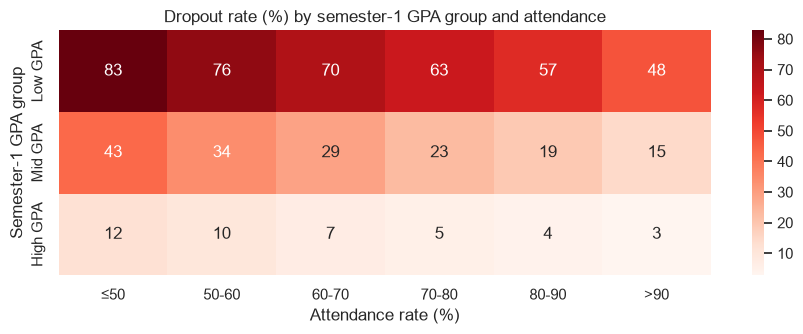

In [121]:
# Does attendance still relate to dropout among students with similar semester-1 GPA?
df["gpa1_group"] = pd.qcut(df["gpa_semester_1"], q=3, labels=["Low GPA", "Mid GPA", "High GPA"])

# Number of students in each cell (to check that no group is too small)
print(pd.crosstab(df["gpa1_group"], df["attendance_bin"]))

pivot = df.pivot_table(index="gpa1_group", columns="attendance_bin",
                       values="dropout", aggfunc="mean", observed=True) * 100

plt.figure(figsize=(9, 3.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds")
plt.title("Dropout rate (%) by semester-1 GPA group and attendance")
plt.xlabel("Attendance rate (%)")
plt.ylabel("Semester-1 GPA group")
plt.tight_layout()
plt.savefig("../reports/figures/gpa_vs_attendance.png", dpi=150)
plt.show()

In [122]:
# GPA range of each semester-1 group
df.groupby("gpa1_group", observed=True)["gpa_semester_1"].agg(["min", "max"]).round(2)

,min,max
gpa1_group,,
Low GPA,0.00,2.23
Mid GPA,2.24,2.94
High GPA,2.95,4.00


## 5.5 GPA x family income level

To check whether the income gap seen in section 4 is explained by grades, dropout rates were compared across family income levels within each `gpa_semester_1` group. The smallest cell contains 6,620 students.

- **The income gap persists within every GPA group, with the same ordering (Low > Middle > High income):** 75% vs. 52% in the Low GPA group (23 points), 33% vs. 15% in the Mid GPA group (18 points) and 9% vs. 3% in the High GPA group (6 points). In the Low GPA group, the gap is close to the unadjusted gap of 22.9 points from section 4.
- **GPA differences remain larger than income differences:** within each income level, the gap between the Low and High GPA groups is 49 to 66 points.
- **Income and GPA are related:** 39.6% of low-income students are in the Low GPA group, compared with 26.5% of high-income students. Part of the unadjusted income gap may therefore reflect differences in GPA, but not all of it.
- In the High GPA group the gap in points is smaller, but the rates are low (9% vs. 3%), so the absolute gap should not be compared directly with the other groups.

This is a descriptive stratified comparison and does not establish causation.

gpa1_group           Low GPA  Mid GPA  High GPA
family_income_level                            
Low                    13785    11602      9422
Middle                 13288    13503     13422
High                    6620     8239     10119


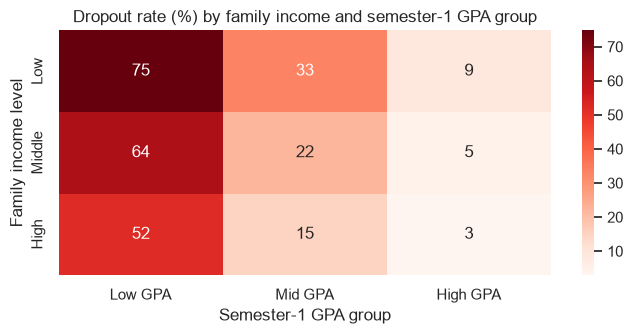

In [123]:
# Does family income still relate to dropout among students with similar semester-1 GPA?
income_order = df.groupby("family_income_level")["dropout"].mean().sort_values(ascending=False).index

print(pd.crosstab(df["family_income_level"], df["gpa1_group"]).loc[income_order])

pivot = df.pivot_table(index="family_income_level", columns="gpa1_group",
                       values="dropout", aggfunc="mean", observed=True).loc[income_order] * 100

plt.figure(figsize=(7, 3.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds")
plt.title("Dropout rate (%) by family income and semester-1 GPA group")
plt.xlabel("Semester-1 GPA group")
plt.ylabel("Family income level")
plt.tight_layout()
plt.savefig("../reports/figures/income_vs_gpa.png", dpi=150)
plt.show()

## 5.6 Unit pass rate

`units_failed` is defined as `units_enrolled` minus `units_passed`, and `units_enrolled` shows almost no association with dropout (r = 0.02). To account for each student's course load, a derived feature was created: pass rate = `units_passed` / `units_enrolled` × 100.

- Pass rate has a stronger correlation with `dropout` (-0.51) than `units_passed` (-0.26) and `units_failed` (+0.47) separately. Among the features in section 5.1, only the two GPAs (-0.57 and -0.52) have a larger absolute correlation.
- The average pass rate is 79.2% (minimum 18.2%, maximum 100%).
- The dropout rate decreases steadily across pass-rate bins, from about 88% (≤50%) to 7% (>90%), a difference of about 82 points. The smallest bin contains 4,885 students.

This is a descriptive association and does not imply causation. Pass rate is derived from variables that may be recorded close to the time of dropout, so its timing should be addressed before modeling.

units_enrolled    0.021
units_passed     -0.261
units_failed      0.467
pass_rate        -0.506
dtype: float64
count    100000.0
mean         79.2
std          15.3
min          18.2
25%          68.8
50%          80.0
75%          90.9
max         100.0
Name: pass_rate, dtype: float64
pass_rate_bin
≤50       4885
50-60     7857
60-70    15712
70-80    23314
80-90    21692
>90      26540
Name: count, dtype: int64


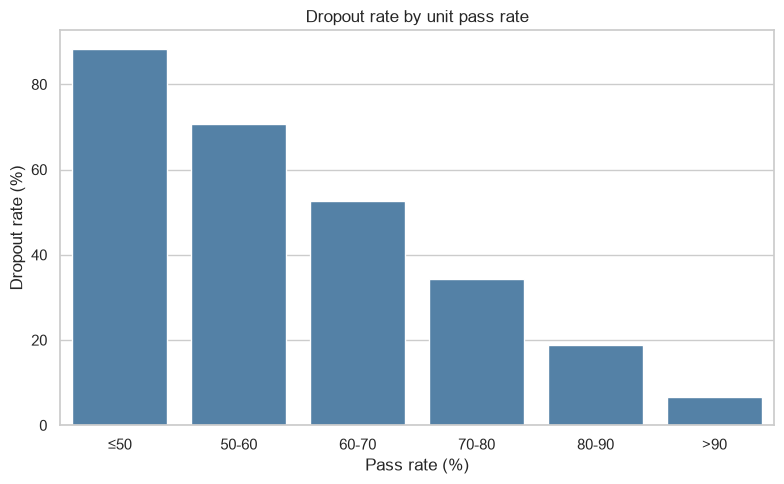

In [124]:
# Pass rate = share of enrolled units that were passed
df["pass_rate"] = df["units_passed"] / df["units_enrolled"] * 100

# Correlation with dropout: counts vs. rate
print(df[["units_enrolled", "units_passed", "units_failed", "pass_rate"]].corrwith(df["dropout"]).round(3))
print(df["pass_rate"].describe().round(1))

# Dropout rate by pass-rate bin (same logic as the attendance chart)
df["pass_rate_bin"] = pd.cut(df["pass_rate"], bins=[0, 50, 60, 70, 80, 90, 100],
                             labels=["≤50", "50-60", "60-70", "70-80", "80-90", ">90"], include_lowest=True)
rate = df.groupby("pass_rate_bin", observed=True)["dropout"].mean() * 100
print(df["pass_rate_bin"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
sns.barplot(x=rate.index.astype(str), y=rate.values, color="steelblue")
plt.title("Dropout rate by unit pass rate")
plt.xlabel("Pass rate (%)")
plt.ylabel("Dropout rate (%)")
plt.tight_layout()
plt.savefig("../reports/figures/dropout_by_pass_rate.png", dpi=150)
plt.show()

## 5.7 Pass rate x GPA

Pass rate is strongly correlated with `gpa_semester_1` (0.83) and `gpa_semester_2` (0.69). To check whether it adds information beyond grades, dropout rates were compared across pass-rate bins within each `gpa_semester_1` group.

The two variables overlap substantially, so several cells are small or empty: there are no High GPA students with a pass rate ≤60%, only 3 Mid GPA students with a pass rate ≤50%, and only 53 Low GPA students with a pass rate >90%. Cells with fewer than about 100 students (those three and High GPA with 60-70%, n = 79) are not interpreted.

Among the remaining cells:

- **Pass rate remains associated with dropout within each GPA group:** from about 88% to 45% in the Low GPA group (≤50% to 80-90%), 37% to 16% in the Mid GPA group (50-60% to >90%), and 10% to 4% in the High GPA group (70-80% to >90%).
- **GPA remains associated with dropout within pass-rate bins:** e.g., about 56%, 26% and 10% in the 70-80% bin, and 45%, 22% and 6% in the 80-90% bin.
- The within-group gaps for pass rate (about 43, 21 and 6 points) cover narrower pass-rate ranges than the overall comparison in 5.6 (≤50% vs. >90%, about 82 points), because the two variables overlap, so they are not directly comparable. The association persists within GPA groups, but its separate contribution cannot be quantified from this table.

This is a descriptive stratified comparison and does not establish independent effects or causation.

                pass_rate  gpa_semester_1  gpa_semester_2
pass_rate            1.00            0.83            0.69
gpa_semester_1       0.83            1.00            0.83
gpa_semester_2       0.69            0.83            1.00
pass_rate_bin   ≤50  50-60  60-70  70-80  80-90    >90
gpa1_group                                            
Low GPA        4882   7480  10045   8535   2698     53
Mid GPA           3    377   5588  11349  10637   5390
High GPA          0      0     79   3430   8357  21097


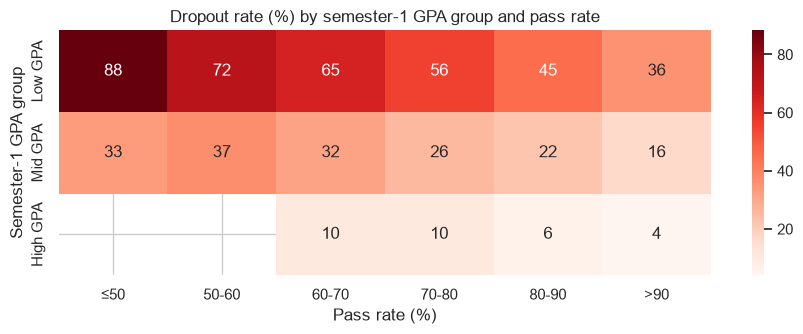

In [125]:
# How related is pass rate to the grades?
print(df[["pass_rate", "gpa_semester_1", "gpa_semester_2"]].corr().round(2))

# Does pass rate still relate to dropout among students with similar semester-1 GPA?
print(pd.crosstab(df["gpa1_group"], df["pass_rate_bin"]))

pivot = df.pivot_table(index="gpa1_group", columns="pass_rate_bin",
                       values="dropout", aggfunc="mean", observed=True) * 100

plt.figure(figsize=(9, 3.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Reds")
plt.title("Dropout rate (%) by semester-1 GPA group and pass rate")
plt.xlabel("Pass rate (%)")
plt.ylabel("Semester-1 GPA group")
plt.tight_layout()
plt.savefig("../reports/figures/gpa_vs_pass_rate.png", dpi=150)
plt.show()

# 6. Key Findings

1. **Baseline:** 32% of the 100,000 students dropped out.
2. **Academic performance shows the strongest association with dropout.** Median semester-1 GPA is 2.87 for students who stayed vs. 1.92 for those who dropped out; median failed units is 2 vs. 4. These academic features overlap strongly with each other (r = 0.83 between the two GPAs, -0.75 between `gpa_semester_1` and `units_failed`).
3. **Attendance remains associated with dropout among students with similar grades:** dropout falls from about 59% (attendance ≤50%) to 16% (>90%) overall, and the pattern holds within each GPA group.
4. **Unit pass rate** (`units_passed` / `units_enrolled`) has a correlation of -0.51 with dropout, stronger than `units_passed` or `units_failed` separately. Dropout falls from about 88% (pass rate ≤50%) to 7% (>90%). It overlaps strongly with grades (r = 0.83 with `gpa_semester_1`); the association persists within GPA groups, over narrower pass-rate ranges.
5. **Financial background is also associated with dropout:** 42.9% (low income), 30.0% (middle) and 20.0% (high). The gap persists within each GPA group, although it is smaller than the gap between GPA groups. Not having tuition up to date (44.2% vs. 28.7%) and having a part-time job (39.8% vs. 24.7%) show gaps of about 15 points each in the unadjusted comparisons of section 4; these were not checked within GPA groups.
6. **Little or no difference** was observed by gender, nationality, course type or international status.

**Limitations:** all findings are descriptive associations. The dataset may be synthetic (e.g., 7,753 students are under 17, and the Kaggle descriptions of several variables state their expected relationship with dropout), so the results illustrate the methodology rather than describe real students. The timing of grade-related variables relative to dropout is not documented.